<a href="https://colab.research.google.com/github/drishikaaneja/flyrank-ml-internship-starter/blob/main/work/notebooks/w07_action_playbook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# W07 · Content Action Playbook (ML-10)

**Lane:** CTR / Engagement Opportunity Scoring (same lane as my capstone).

This notebook turns the validated output of my CTR model into a **human-reviewed content action playbook**:

1. Ranked actions + reason codes (with archetype → action mapping, decay/refresh insight and cost/value)
2. Intended use and limits
3. Human review rules + the no-go list
4. Monitoring / retrain triggers
5. Exports for the paper
6. Self-check

**Data:** FlyRank internship warehouse, release `v20260703` (pseudonymised). Main table `fact_content_query_90d` (90-day window), joined to `dim_content`.

**How to run:** store a Hugging Face read token as a Colab secret named `HF_TOKEN1`, then **Runtime → Run all**. The modelling step takes about 10 minutes.

In [2]:
!pip install -q duckdb huggingface_hub

import os, json
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from google.colab import userdata
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from scipy.stats import spearmanr

HF_TOKEN = userdata.get("HF_TOKEN1")          # stored as a Colab secret, never printed
BASE = "hf://datasets/FlyRank/internship-warehouse"
Q = f"{BASE}/fact_content_query_90d.parquet"
C = f"{BASE}/dim_content.parquet"

os.makedirs("work/outputs", exist_ok=True)
os.makedirs("work/figures", exist_ok=True)

con = duckdb.connect()
con.execute(f"CREATE SECRET hf (TYPE huggingface, TOKEN '{HF_TOKEN}')")

MIN_PAGE_IMPRESSIONS = 500      # pages below this are too noisy to act on
EXPECTED_ROWS = 2_274_658       # row count from the capstone, used as a leakage / duplication check
print("Setup done")

Setup done


## 0 · Load data and rebuild the validated scores

Same data, exclusions and model as the capstone:

- Exclude rows with zero impressions and rows with average position below 1 (invalid).
- Target = query-level CTR, weighted by impressions.
- Baseline = pooled CTR by position bucket (1–19, 20+), learned from training clients only.
- Model = `HistGradientBoostingRegressor` with 8 features, **no click-derived features**.
- 5-fold `GroupKFold` grouped by client. Every row is scored **out of fold**, so a page is never scored by a model that saw its client.

New for this week: the last-30 / previous-30 day sub-windows, used for the decay / refresh insight.

In [3]:
data = con.sql(f"""
    SELECT q.client_hash_id, q.content_hash_id,
           q.impressions_90d AS imp, q.clicks_90d AS clicks, q.avg_position_90d AS position,
           q.impressions_last30 AS imp_last30, q.clicks_last30,
           q.impressions_prev30 AS imp_prev30, q.clicks_prev30,
           q.query_token_count, q.query_char_count,
           c.word_count, c.content_type, c.main_intent, c.competition, c.search_volume
    FROM '{Q}' q
    LEFT JOIN '{C}' c USING (client_hash_id, content_hash_id)
    WHERE q.impressions_90d > 0 AND q.avg_position_90d >= 1
""").df()

print("Rows:", len(data), "| expected:", EXPECTED_ROWS, "| match:", len(data) == EXPECTED_ROWS)
print("Clients:", data.client_hash_id.nunique())

data["pos_bucket"] = data["position"].clip(upper=20).round()
for col in ["content_type", "main_intent"]:
    data[col] = data[col].astype("category")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Rows: 2274658 | expected: 2274658 | match: True
Clients: 52


In [4]:
FEATURES = ["position", "query_token_count", "query_char_count", "word_count",
            "content_type", "main_intent", "competition", "search_volume"]

gkf = GroupKFold(n_splits=5)
data["oof_ctr"] = np.nan
data["base_ctr"] = np.nan
fold_rows = []

for i, (tr, te) in enumerate(gkf.split(data, groups=data["client_hash_id"])):
    train, test = data.iloc[tr], data.iloc[te]

    norm = train.groupby("pos_bucket")[["clicks", "imp"]].sum()
    base_curve = norm["clicks"] / norm["imp"]
    b = test["pos_bucket"].map(base_curve).fillna(0).values

    m = HistGradientBoostingRegressor(categorical_features="from_dtype", max_iter=200, random_state=42)
    m.fit(train[FEATURES], train["clicks"] / train["imp"], sample_weight=train["imp"])
    p = m.predict(test[FEATURES]).clip(0, 1)

    data.loc[data.index[te], "oof_ctr"] = p
    data.loc[data.index[te], "base_ctr"] = b

    t = test[["content_hash_id", "imp", "clicks"]].copy()
    t["base_clicks"] = t["imp"].values * b
    t["model_clicks"] = t["imp"].values * p
    pg_f = t.groupby("content_hash_id")[["imp", "clicks", "base_clicks", "model_clicks"]].sum()
    pg_f = pg_f[pg_f["imp"] >= MIN_PAGE_IMPRESSIONS]

    fold_rows.append({
        "fold": i + 1,
        "test_pages": int(len(pg_f)),
        "base_error": float((pg_f["base_clicks"] - pg_f["clicks"]).abs().mean()),
        "model_error": float((pg_f["model_clicks"] - pg_f["clicks"]).abs().mean()),
        "base_spearman": float(spearmanr(pg_f["base_clicks"], pg_f["clicks"]).correlation),
        "model_spearman": float(spearmanr(pg_f["model_clicks"], pg_f["clicks"]).correlation),
    })
    print(f"Fold {i+1} done")

folds = pd.DataFrame(fold_rows).set_index("fold")
print(folds.round(3))
print("\nAverage:")
print(folds.mean().round(3))

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done
      test_pages  base_error  model_error  base_spearman  model_spearman
fold                                                                    
1          10552       8.212        7.346          0.812           0.816
2           6932       7.272        9.171          0.560           0.571
3           7286       6.947        6.517          0.693           0.710
4           6695       9.904        9.605          0.673           0.688
5           7555       7.970        8.008          0.752           0.765

Average:
test_pages        7804.000
base_error           8.061
model_error          8.129
base_spearman        0.698
model_spearman       0.710
dtype: float64


## 1 · Ranked actions + reason codes

### 1a · Page-level scores, reason codes and trend

- **Missing clicks** = expected clicks (out-of-fold model) − actual clicks over the 90-day window.
- **Reason code** (same rules as the capstone): `ZERO_CLICKS`, `OK_PROTECT`, `TOP3_LOW_CTR`, `PAGE1_LOW_CTR`, `PAGE2_LOW_CTR`.
- **Trend** (decay / refresh insight) compares clicks in the last 30 days with the previous 30 days:
  - `DECLINING` if clicks fell by 20% or more, `GROWING` if they rose by 25% or more, otherwise `STABLE`
  - `LOW_SIGNAL` if both windows have fewer than 10 clicks (too few to judge)

In [5]:
data["exp_clicks"] = data["imp"] * data["oof_ctr"]
data["pos_x_imp"] = data["position"] * data["imp"]

pg = data.groupby("content_hash_id").agg(
    impressions=("imp", "sum"),
    clicks=("clicks", "sum"),
    expected_clicks=("exp_clicks", "sum"),
    pos_x_imp=("pos_x_imp", "sum"),
    searches=("imp", "size"),
    clicks_last30=("clicks_last30", "sum"),
    clicks_prev30=("clicks_prev30", "sum"),
).reset_index()

pg["position"] = pg["pos_x_imp"] / pg["impressions"]
pg = pg[pg["impressions"] >= MIN_PAGE_IMPRESSIONS].drop(columns="pos_x_imp").copy()
pg["missing_clicks"] = pg["expected_clicks"] - pg["clicks"]
pg["click_ratio"] = pg["clicks"] / pg["expected_clicks"]

# Reason codes (identical rules to the capstone)
pg["reason"] = np.select(
    [
        (pg["clicks"] == 0) & (pg["impressions"] >= 5000),
        pg["click_ratio"] >= 1,
        pg["position"] <= 3,
        pg["position"] <= 10,
    ],
    ["ZERO_CLICKS", "OK_PROTECT", "TOP3_LOW_CTR", "PAGE1_LOW_CTR"],
    default="PAGE2_LOW_CTR",
)

# Trend: last 30 days vs previous 30 days
ratio = (pg["clicks_last30"] + 1) / (pg["clicks_prev30"] + 1)
pg["trend"] = np.select(
    [
        (pg["clicks_last30"] < 10) & (pg["clicks_prev30"] < 10),
        ratio <= 0.8,
        ratio >= 1.25,
    ],
    ["LOW_SIGNAL", "DECLINING", "GROWING"],
    default="STABLE",
)

print("Pages analysed:", len(pg))
print("\nReason codes:")
print(pg["reason"].value_counts())
print("\nTrend:")
print(pg["trend"].value_counts())
print("\nReason code x trend:")
print(pd.crosstab(pg["reason"], pg["trend"]))

Pages analysed: 39020

Reason codes:
reason
OK_PROTECT       14192
PAGE2_LOW_CTR    13088
PAGE1_LOW_CTR    10904
TOP3_LOW_CTR       451
ZERO_CLICKS        385
Name: count, dtype: int64

Trend:
trend
LOW_SIGNAL    34956
DECLINING      2190
GROWING        1129
STABLE          745
Name: count, dtype: int64

Reason code x trend:
trend          DECLINING  GROWING  LOW_SIGNAL  STABLE
reason                                               
OK_PROTECT          1470      820       11400     502
PAGE1_LOW_CTR        610      272        9825     197
PAGE2_LOW_CTR         78       26       12956      28
TOP3_LOW_CTR          32       11         390      18
ZERO_CLICKS            0        0         385       0


### 1b · Archetype → action mapping

Each page falls into one archetype. Each archetype has one action, an owner and an **assumed** effort (hours per page). The effort numbers are planning assumptions, not measured values.

| Archetype | Rule | Action | Effort (h) |
|---|---|---|---|
| Silent page | `ZERO_CLICKS` | **CHECK** – confirm the page is live, indexed and tracked before any edit | 0.25 |
| Visible but ignored | `TOP3_LOW_CTR` | **REWRITE_METADATA** – rewrite title and meta description | 0.5 |
| Page-one under-clicker | `PAGE1_LOW_CTR` | **REWRITE_SNIPPET** – rewrite snippet and check the page matches searcher intent | 1.0 |
| Almost there | `PAGE2_LOW_CTR` | **IMPROVE_CONTENT** – improve content to reach page 1 first | 4.0 |
| Decaying performer | `OK_PROTECT` + `DECLINING` | **REFRESH_REVIEW** – review whether the content is out of date | 2.0 |
| Healthy | `OK_PROTECT` otherwise | **PROTECT** – no change, monitor only | 0 |

                                         pages  missing_clicks  effort_hours
archetype              action                                               
Almost there           IMPROVE_CONTENT   13088         30658.0       52352.0
Healthy                PROTECT           12722             0.0           0.0
Page-one under-clicker REWRITE_SNIPPET   10904        116863.0       10904.0
Decaying performer     REFRESH_REVIEW     1470             0.0        2940.0
Visible but ignored    REWRITE_METADATA    451         13508.0         226.0
Silent page            CHECK               385          9093.0          96.0


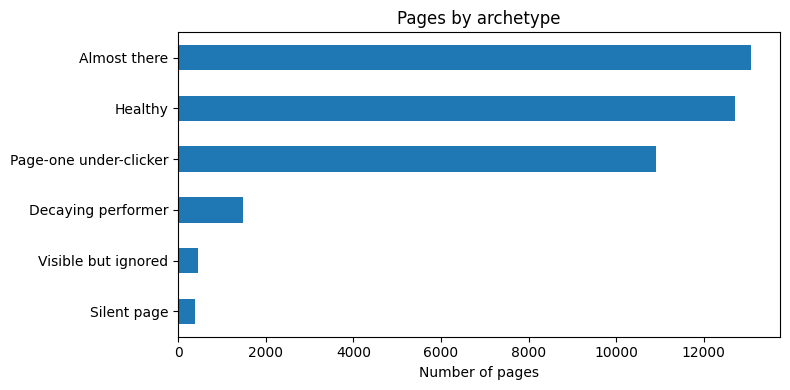

In [6]:
ARCHETYPES = {
    "ZERO_CLICKS":   ("Silent page",            "CHECK",            0.25),
    "TOP3_LOW_CTR":  ("Visible but ignored",    "REWRITE_METADATA", 0.5),
    "PAGE1_LOW_CTR": ("Page-one under-clicker", "REWRITE_SNIPPET",  1.0),
    "PAGE2_LOW_CTR": ("Almost there",           "IMPROVE_CONTENT",  4.0),
}

def assign(row):
    if row["reason"] == "OK_PROTECT":
        if row["trend"] == "DECLINING":
            return ("Decaying performer", "REFRESH_REVIEW", 2.0)
        return ("Healthy", "PROTECT", 0.0)
    return ARCHETYPES[row["reason"]]

pg[["archetype", "action", "effort_hours"]] = pg.apply(assign, axis=1, result_type="expand")

summary = pg.groupby(["archetype", "action"]).agg(
    pages=("content_hash_id", "size"),
    missing_clicks=("missing_clicks", lambda s: s.clip(lower=0).sum()),
    effort_hours=("effort_hours", "sum"),
).sort_values("pages", ascending=False)
print(summary.round(0))

fig, ax = plt.subplots(figsize=(8, 4))
summary["pages"].droplevel(1).plot(kind="barh", ax=ax)
ax.invert_yaxis()
ax.set_xlabel("Number of pages")
ax.set_ylabel("")
ax.set_title("Pages by archetype")
plt.tight_layout()
plt.savefig("work/figures/w07_archetypes.png", dpi=150)
plt.show()

### 1c · The ranked action queue

The queue contains every page whose action is not `PROTECT`, split into two lists because their values are measured differently:

- **Under-performers** (CHECK, REWRITE_METADATA, REWRITE_SNIPPET, IMPROVE_CONTENT) ranked by **missing clicks over 90 days**, the same ranking as the capstone.
- **Refresh watchlist** (REFRESH_REVIEW) ranked by **clicks lost** between the previous and the last 30 days.

**Cost / value:** `value_per_hour = missing_clicks / effort_hours` shows which fixes are cheapest per click recovered. It is a planning aid only, since both the gap and the effort are estimates.

In [7]:
under = pg[pg["action"].isin(["CHECK", "REWRITE_METADATA", "REWRITE_SNIPPET", "IMPROVE_CONTENT"])].copy()
under = under.sort_values("missing_clicks", ascending=False)
under["rank"] = np.arange(1, len(under) + 1)
under["value_per_hour"] = under["missing_clicks"] / under["effort_hours"]

refresh = pg[pg["action"] == "REFRESH_REVIEW"].copy()
refresh["clicks_lost_30d"] = refresh["clicks_prev30"] - refresh["clicks_last30"]
refresh = refresh.sort_values("clicks_lost_30d", ascending=False)
refresh["rank"] = np.arange(1, len(refresh) + 1)

cols = ["rank", "content_hash_id", "archetype", "action", "trend", "impressions", "clicks",
        "expected_clicks", "position", "missing_clicks", "effort_hours", "value_per_hour"]
print("Top 15 under-performers:")
print(under[cols].head(15).round(1).to_string(index=False))

print("\nTop 10 refresh watchlist:")
print(refresh[["rank", "content_hash_id", "clicks_prev30", "clicks_last30", "clicks_lost_30d", "position"]]
      .head(10).round(1).to_string(index=False))

# How many under-performers are also declining? (decay overlay)
print("\nUnder-performers that are also DECLINING:", int((under["trend"] == "DECLINING").sum()), "of", len(under))

Top 15 under-performers:
 rank          content_hash_id              archetype           action      trend  impressions  clicks  expected_clicks  position  missing_clicks  effort_hours  value_per_hour
    1 content_15168cd1c94e3529 Page-one under-clicker  REWRITE_SNIPPET  DECLINING       311895     178           4875.7       3.5          4697.7           1.0          4697.7
    2 content_943dc881428182b8    Visible but ignored REWRITE_METADATA     STABLE       606831     344           3352.9       2.0          3008.9           0.5          6017.9
    3 content_d0acf7062bc6b257    Visible but ignored REWRITE_METADATA  DECLINING       297755      33           1152.2       2.1          1119.2           0.5          2238.4
    4 content_4c15fe8dc370f3cd Page-one under-clicker  REWRITE_SNIPPET  DECLINING       266229     459           1559.8       3.0          1100.8           1.0          1100.8
    5 content_bddfdd871aa09fbe    Visible but ignored REWRITE_METADATA LOW_SIGNAL       156932 

Top 10% of under-performers (2482 pages): 69.8% of missing clicks, about 3284 assumed hours
Same 3284 hours ordered by value per hour: 73.5% of missing clicks


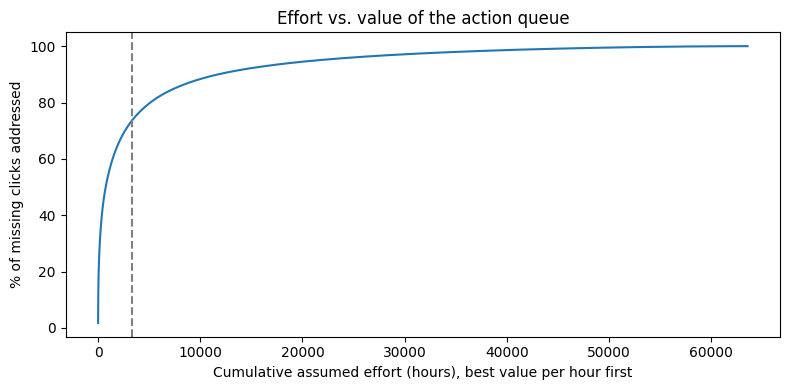

In [8]:
# Cost / value: how much of the gap can be covered for how much effort?
mc = under["missing_clicks"].clip(lower=0)
top10_n = max(1, int(len(under) * 0.10))
top10_share = mc.iloc[:top10_n].sum() / mc.sum() * 100
top10_hours = under["effort_hours"].iloc[:top10_n].sum()
print(f"Top 10% of under-performers ({top10_n} pages): {top10_share:.1f}% of missing clicks, about {top10_hours:.0f} assumed hours")

# Same budget, ordered by value per hour instead
by_vph = under.sort_values("value_per_hour", ascending=False)
cum_hours = by_vph["effort_hours"].cumsum()
cum_value = by_vph["missing_clicks"].clip(lower=0).cumsum() / mc.sum() * 100
within_budget = cum_value[cum_hours <= top10_hours]
vph_share = float(within_budget.iloc[-1]) if len(within_budget) else 0.0
print(f"Same {top10_hours:.0f} hours ordered by value per hour: {vph_share:.1f}% of missing clicks")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(cum_hours.values, cum_value.values)
ax.axvline(top10_hours, linestyle="--", color="grey")
ax.set_xlabel("Cumulative assumed effort (hours), best value per hour first")
ax.set_ylabel("% of missing clicks addressed")
ax.set_title("Effort vs. value of the action queue")
plt.tight_layout()
plt.savefig("work/figures/w07_effort_vs_value.png", dpi=150)
plt.show()

## 2 · Intended use and limits

**Intended use**
- Decision support for a content / SEO team deciding **which pages to review first** and **what kind of review** each needs.
- Works on one 90-day window of pseudonymised data, at page level, for pages with at least 500 impressions.
- Users: editors and SEO specialists who will look at each page before changing anything.

**Not intended for**
- Automatically changing, publishing, merging or deleting content.
- Forecasting future traffic, or promising that a fix will recover a specific number of clicks.
- Explaining how Google ranks pages, or claiming that a change *caused* a gain.
- Judging the performance of writers, teams or clients.

**Known limits**
- **Observational:** missing clicks is a gap against what similar positions received in this data, not a causal estimate.
- **Single window:** one 90-day release, so stability over time is unknown.
- **Few clients:** 52 clients have query data; fold-to-fold variation is larger than the model's gain over the baseline.
- **Small model gain:** the model ranks pages slightly but consistently better than position alone, but does not reliably reduce click-count error.
- **Averaged positions:** each query uses a 90-day average position.
- **Assumed thresholds and efforts:** the 500-impression cut-off, the trend thresholds and the effort hours are planning choices, not tuned or measured values.
- **ZERO_CLICKS** may be tracking or reporting problems, not real behaviour.

## 3 · Human review rules + the no-go list

**Human review rules**
1. **Every action is reviewed by a person** before anything is published. The queue suggests; an editor decides.
2. **Check intent first:** before rewriting, the editor confirms the page actually answers what searchers are looking for.
3. **CHECK before editing:** `ZERO_CLICKS` pages are verified (live, indexed, tracked) before any content change.
4. **Leave PROTECT pages alone** unless there is a separate business reason.
5. **One change at a time per page**, logged with a date, so later before/after comparisons are at least interpretable (still observational).
6. **Cap the weekly batch** (for example 20 pages per client per week) so changes stay reviewable and their effects are not mixed together.
7. **Skip LOW_SIGNAL trend calls:** don't treat a page as decaying or growing on fewer than 10 clicks.

**No-go list – never automate**
- Auto-generating and publishing titles, meta descriptions or content.
- Deleting, merging, redirecting or noindexing pages based on this score.
- Acting on pages below 500 impressions.
- Using scores to rank or evaluate writers, teams or clients.
- Reporting "missing clicks" as guaranteed recoverable traffic, or as proof of how Google ranks.
- Re-identifying clients, domains or queries from the hashes.

## 4 · Monitoring / retrain triggers

The cell below saves a **reference snapshot** (CTR by position, validation scores, archetype mix) into the metrics JSON. When a new release or 90-day window arrives, compare against it.

**Rescore (no retrain)** when a new 90-day window is available.

**Retrain** if any of these happen on the new window:
1. **Position curve drift:** pooled CTR at positions 1–3 moves by more than **25% (relative)** from the reference.
2. **Model stops helping:** the model's Spearman is not above the baseline's in at least **3 of 5** client folds.
3. **Data shape change:** row count or number of clients changes by more than **10%**.
4. **Tracking warning:** the share of `ZERO_CLICKS` pages **doubles** (likely a tracking problem; investigate before trusting any scores).

These are light, practical checks for a non-production plan, not a full monitoring system.

In [9]:
curve = data.groupby("pos_bucket")[["clicks", "imp"]].sum()
curve["ctr"] = curve["clicks"] / curve["imp"]
ref_curve = {str(int(k)): float(v) for k, v in curve["ctr"].items()}

def check_new_window(new_curve, new_folds, new_rows, new_clients, new_zero_share):
    """Compare a new window against the saved reference. Returns a list of triggered retrain reasons."""
    reasons = []
    for pos in ["1", "2", "3"]:
        old, new = ref_curve[pos], new_curve.get(pos, 0)
        if old > 0 and abs(new - old) / old > 0.25:
            reasons.append(f"CTR at position {pos} moved more than 25%")
    if (new_folds["model_spearman"] > new_folds["base_spearman"]).sum() < 3:
        reasons.append("Model beats baseline in fewer than 3 of 5 folds")
    if abs(new_rows - len(data)) / len(data) > 0.10:
        reasons.append("Row count changed by more than 10%")
    if abs(new_clients - data.client_hash_id.nunique()) / data.client_hash_id.nunique() > 0.10:
        reasons.append("Client count changed by more than 10%")
    ref_zero = (pg["reason"] == "ZERO_CLICKS").mean()
    if (ref_zero > 0 and new_zero_share >= 2 * ref_zero) or (ref_zero == 0 and new_zero_share > 0.01):
        reasons.append("ZERO_CLICKS share doubled")
    return reasons

# Sanity check: comparing the current window with itself should trigger nothing
print("Triggers on current window (should be empty):",
      check_new_window(ref_curve, folds, len(data), data.client_hash_id.nunique(),
                       (pg["reason"] == "ZERO_CLICKS").mean()))

Triggers on current window (should be empty): []


## 5 · Exports for the paper

- `work/outputs/w07_action_queue.csv` – the full ranked queue. **Not committed** (data files stay out of git; this notebook regenerates it).
- `work/outputs/w07_playbook_metrics.json` – summary numbers and the monitoring reference. **Committed** as the receipt for the paper's numbers.
- `work/figures/w07_archetypes.png` and `work/figures/w07_effort_vs_value.png` – **committed** for reuse in the paper.

In [10]:
queue = pd.concat([
    under.assign(list_name="under_performers"),
    refresh.assign(list_name="refresh_watchlist"),
], ignore_index=True)

queue_cols = ["list_name", "rank", "content_hash_id", "archetype", "action", "reason", "trend",
              "impressions", "clicks", "expected_clicks", "position", "missing_clicks",
              "clicks_prev30", "clicks_last30", "effort_hours", "value_per_hour"]
queue = queue.reindex(columns=queue_cols)
queue.to_csv("work/outputs/w07_action_queue.csv", index=False)

def num(x):
    return float(x) if isinstance(x, (np.floating, float)) else int(x)

metrics = {
    "assignment": "ML-10 Content Action Playbook",
    "lane": "CTR / Engagement Opportunity Scoring",
    "release": "v20260703",
    "rows": int(len(data)),
    "clients": int(data.client_hash_id.nunique()),
    "pages_analysed": int(len(pg)),
    "min_page_impressions": MIN_PAGE_IMPRESSIONS,
    "validation": {
        "folds": folds.reset_index().to_dict(orient="records"),
        "mean": {k: float(v) for k, v in folds.mean().items()},
        "model_better_spearman_folds": int((folds["model_spearman"] > folds["base_spearman"]).sum()),
        "model_better_error_folds": int((folds["model_error"] < folds["base_error"]).sum()),
    },
    "reason_codes": {k: int(v) for k, v in pg["reason"].value_counts().items()},
    "trend": {k: int(v) for k, v in pg["trend"].value_counts().items()},
    "archetypes": {k: int(v) for k, v in pg["archetype"].value_counts().items()},
    "queue": {
        "under_performers": int(len(under)),
        "refresh_watchlist": int(len(refresh)),
        "top10pct_pages": int(top10_n),
        "top10pct_share_missing_clicks": round(float(top10_share), 1),
        "top10pct_assumed_hours": round(float(top10_hours), 1),
        "same_hours_by_value_per_hour_share": round(float(vph_share), 1),
    },
    "effort_hours_assumed": {"CHECK": 0.25, "REWRITE_METADATA": 0.5, "REWRITE_SNIPPET": 1.0,
                             "IMPROVE_CONTENT": 4.0, "REFRESH_REVIEW": 2.0, "PROTECT": 0.0},
    "monitoring_reference": {
        "ctr_by_position_bucket": ref_curve,
        "zero_clicks_share": float((pg["reason"] == "ZERO_CLICKS").mean()),
        "retrain_triggers": [
            "CTR at positions 1-3 moves >25% relative to reference",
            "Model Spearman above baseline in fewer than 3 of 5 client folds",
            "Row or client count changes >10%",
            "ZERO_CLICKS share doubles",
        ],
    },
}

with open("work/outputs/w07_playbook_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2, default=num)

for p in ["work/outputs/w07_action_queue.csv", "work/outputs/w07_playbook_metrics.json",
          "work/figures/w07_archetypes.png", "work/figures/w07_effort_vs_value.png"]:
    print(p, "->", os.path.getsize(p), "bytes")

work/outputs/w07_action_queue.csv -> 5110119 bytes
work/outputs/w07_playbook_metrics.json -> 3658 bytes
work/figures/w07_archetypes.png -> 38335 bytes
work/figures/w07_effort_vs_value.png -> 49146 bytes


## 6 · Self-check

In [11]:
checks = {
    "Row count matches the capstone (no duplicated rows from the join)": len(data) == EXPECTED_ROWS,
    "Every row has an out-of-fold score": data["oof_ctr"].notna().all(),
    "Every page has a reason code, archetype and action": pg[["reason", "archetype", "action"]].notna().all().all(),
    "Under-performer queue is sorted by missing clicks": under["missing_clicks"].is_monotonic_decreasing,
    "No PROTECT pages in the queue": not (queue["action"] == "PROTECT").any(),
    "Only hashed IDs in the queue (no URLs or query text)": queue["content_hash_id"].str.startswith("content_").all(),
    "Queue CSV exported": os.path.exists("work/outputs/w07_action_queue.csv"),
    "Metrics JSON exported": os.path.exists("work/outputs/w07_playbook_metrics.json"),
    "Figures exported": all(os.path.exists(p) for p in ["work/figures/w07_archetypes.png",
                                                         "work/figures/w07_effort_vs_value.png"]),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
print("\nAll checks passed" if all(checks.values()) else "\nSome checks FAILED - look above")

PASS - Row count matches the capstone (no duplicated rows from the join)
PASS - Every row has an out-of-fold score
PASS - Every page has a reason code, archetype and action
PASS - Under-performer queue is sorted by missing clicks
PASS - No PROTECT pages in the queue
PASS - Only hashed IDs in the queue (no URLs or query text)
PASS - Queue CSV exported
PASS - Metrics JSON exported
PASS - Figures exported

All checks passed


**Checklist against "what done looks like"**

- [x] Intended use – section 2
- [x] Ranked actions + reason codes – section 1
- [x] Archetype → action mapping – section 1b
- [x] Decay / refresh insight – trend in 1a, refresh watchlist in 1c
- [x] Human review rules – section 3
- [x] Monitoring / retrain triggers – section 4
- [x] Cost / value – section 1c
- [x] No-go cases (what should NOT be automated) – section 3
- [x] Queue exported for the paper – section 5
- [x] Practical and non-production – no automation, human review on every action

In [12]:
# Download the files that need to be committed (the CSV stays out of git)
from google.colab import files
for p in ["work/outputs/w07_playbook_metrics.json",
          "work/figures/w07_archetypes.png",
          "work/figures/w07_effort_vs_value.png"]:
    files.download(p)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>